In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 2.4

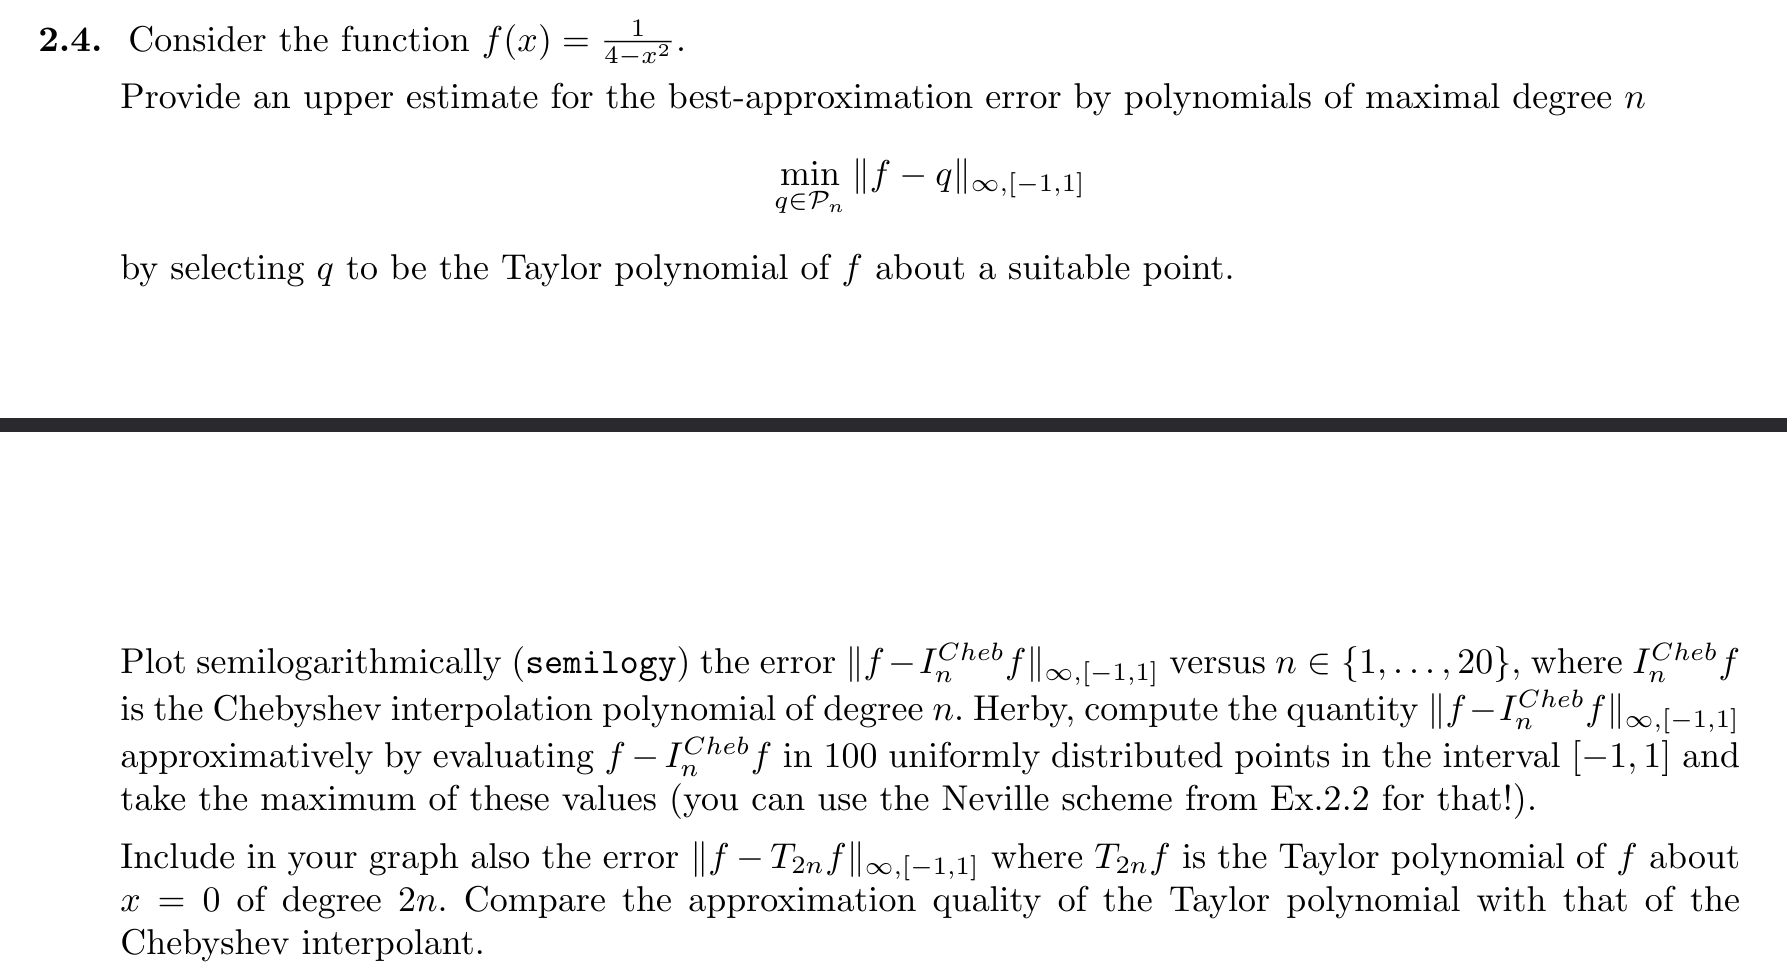

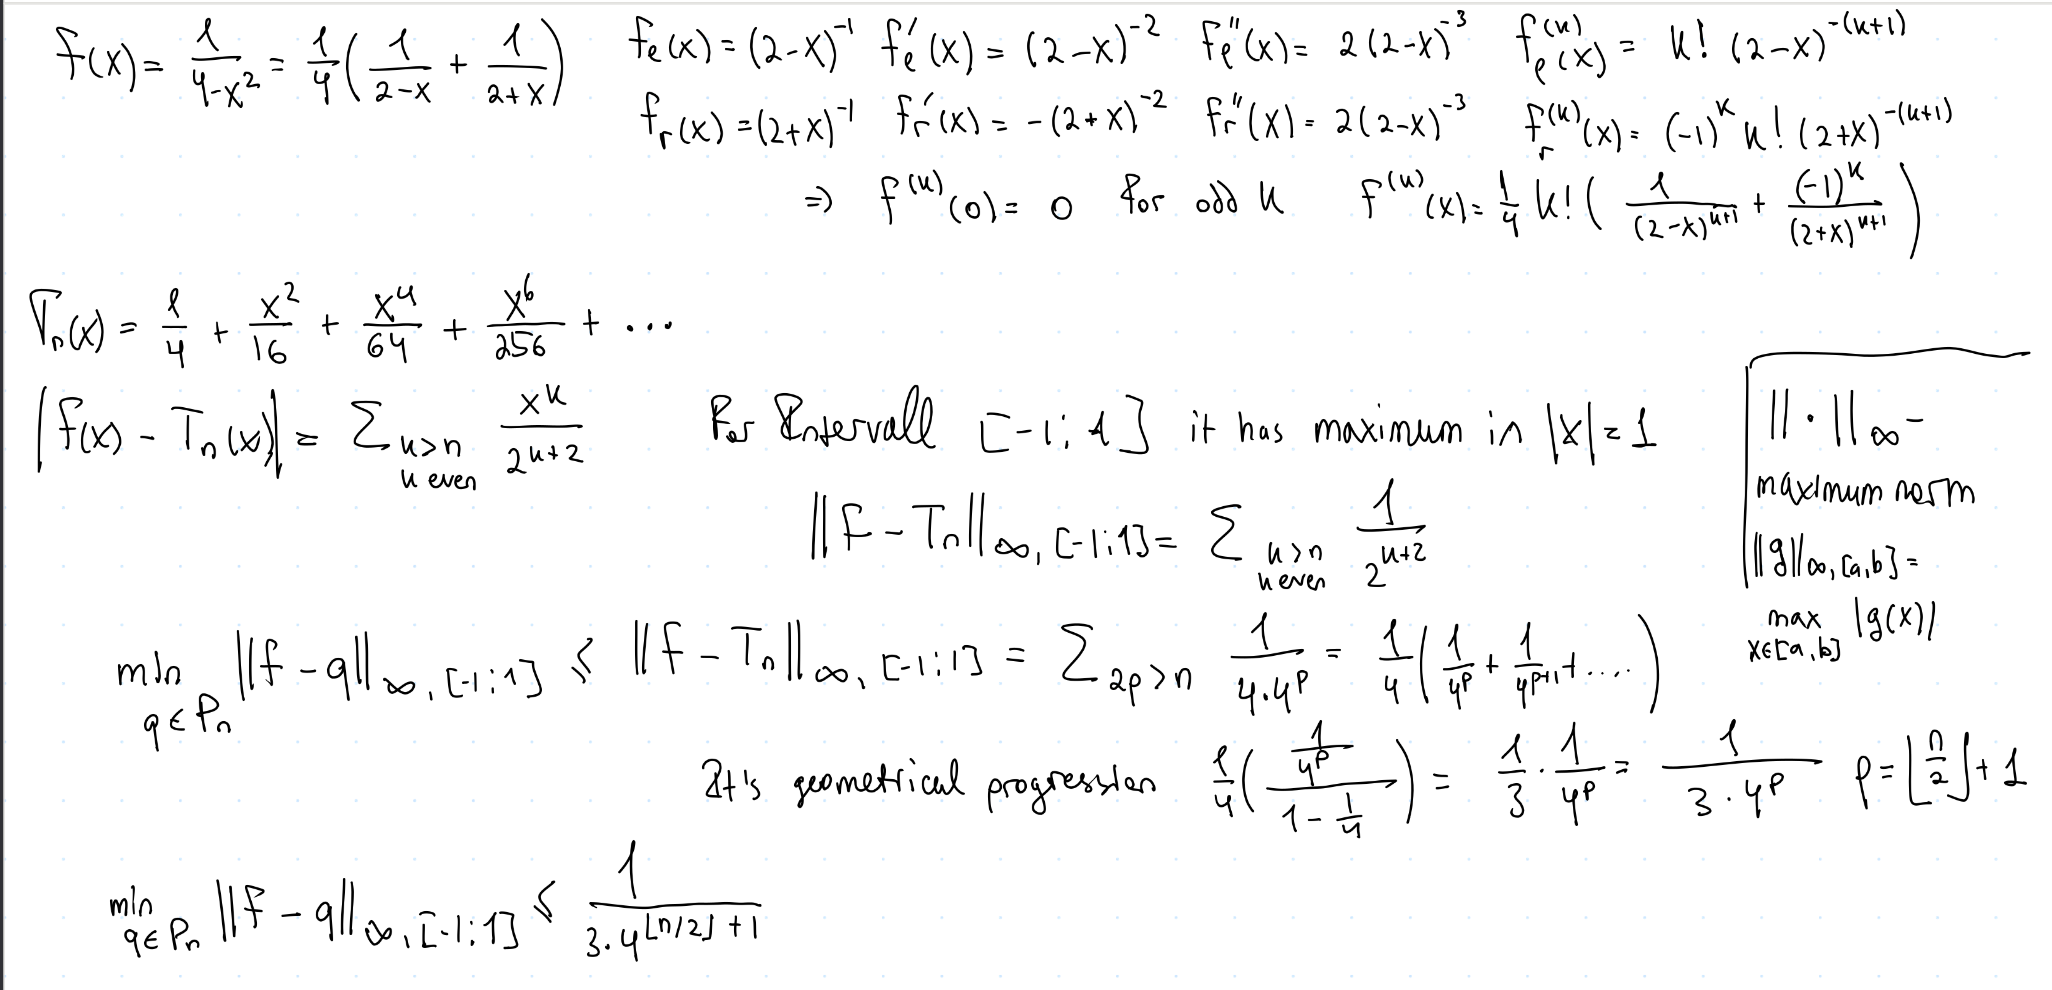

In [5]:
f   = lambda x:  1 / (4 - x**2)
n = 20

def neville_schema(x, f, x0):
    n = len(x) - 1  
    N = np.zeros((n + 1, n + 1))
    N[:, 0] = f
    for m in range(1, n + 1):
        for j in range(0, n - m + 1):
            N[j, m] = ((x0 - x[j]) * N[j + 1, m - 1] - (x0 - x[j + m]) * N[j, m - 1]) \
                    / (x[j + m] - x[j])
    return N

errors_cheb = []
t = np.linspace(-1, 1, 100)
for n in range(1, n + 1):
    x = np.polynomial.chebyshev.chebpts1(n + 1)
    fx = f(x)
    p_t = np.array([neville_schema(x, fx, ti)[0, n] for ti in t])
    errors_cheb.append(np.max(np.abs(f(t) - p_t)))

errors_cheb

[np.float64(0.047619047619047616),
 np.float64(0.0064102564102563875),
 np.float64(0.0034364261168383647),
 np.float64(0.0004604051565377243),
 np.float64(0.000246730816678864),
 np.float64(3.3055665741077433e-05),
 np.float64(1.7714478042885062e-05),
 np.float64(2.373290044377363e-06),
 np.float64(1.271842301586723e-06),
 np.float64(1.7039455862954966e-07),
 np.float64(9.131416889296418e-08),
 np.float64(1.2233778989845234e-08),
 np.float64(6.556062470686186e-09),
 np.float64(8.783458960159862e-10),
 np.float64(4.707040868190404e-10),
 np.float64(6.306233313324583e-11),
 np.float64(3.379491131383361e-11),
 np.float64(4.527711539026313e-12),
 np.float64(2.426281398015817e-12),
 np.float64(3.249622793077833e-13)]

In [7]:
def Tn_error(n):
    return 1 / (3 * (4 ** (n + 1)))

errors_taylor = [Tn_error(n) for n in range(1, 21)]
errors_taylor

[0.020833333333333332,
 0.005208333333333333,
 0.0013020833333333333,
 0.0003255208333333333,
 8.138020833333333e-05,
 2.0345052083333332e-05,
 5.086263020833333e-06,
 1.2715657552083333e-06,
 3.178914388020833e-07,
 7.947285970052083e-08,
 1.9868214925130207e-08,
 4.967053731282552e-09,
 1.241763432820638e-09,
 3.104408582051595e-10,
 7.761021455128987e-11,
 1.9402553637822468e-11,
 4.850638409455617e-12,
 1.2126596023639042e-12,
 3.0316490059097606e-13,
 7.579122514774402e-14]

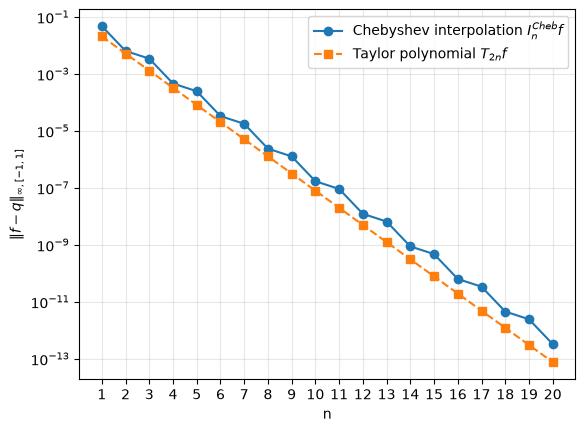

In [8]:
ns = np.arange(1, 21)

plt.semilogy(ns, errors_cheb, 'o-', label='Chebyshev interpolation $I_n^{Cheb} f$')
plt.semilogy(ns, errors_taylor, 's--', label='Taylor polynomial $T_{2n} f$')

plt.xlabel('n')
plt.ylabel(r'$\|f - q\|_{\infty,[-1,1]}$')
plt.xticks(ns)
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()